In [5]:
import sys; sys.path.insert(0, "..")
from common import *

import json
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display
from PIL import Image
from scipy import ndimage
from tqdm import tqdm

RUN_NAME   = "SmoothLumen_DAv2_Small"
MODEL_ID   = "depth-anything/Depth-Anything-V2-Small-hf"
PRED_DIR   = None                 # folder with the teammate's *_pred.npy files, or None to run the model here
MASK       = "exclude_clipped"    # group rule. "include_clipped" = the old notebook (gt_raw > 0)
DMAX       = 100.0
BIN_EDGES  = np.array([0, 20, 40, 60, 80, 100], dtype=np.float32)
CENTERS    = (BIN_EDGES[:-1] + BIN_EDGES[1:]) / 2      # 10, 30, 50, 70, 90 mm
MIN_PIXELS = 2000                 # minimum (weighted) pixels in a bin
FIT_STRIDE = 4                    # fit on every 4th valid pixel (speed). Evaluation uses all pixels.
N_BLOCKS, GAP = 4, 2              # block cross-validation
CUES       = ["both", "dark", "far"]   # use ["both"] if memory is low
SIGMA, TAU = 20, 0.5              # lumen detector settings (fixed on dev, not fitted)
RANGES     = [(0, 20), (20, 40), (40, 60), (60, 100)]

out_dir = stream_results_dir(CFG, f"{RUN_NAME}_{MASK}")
fig_dir = out_dir / "figures"
fig_dir.mkdir(exist_ok=True)
dev_paths = list_frames(CFG, "dev")

ALL_METHODS = [
    ("Constant median",               "constant", None),
    ("DAv2 + global linear",          "linear",   None),
    ("+ smooth correction",           "smooth",   None),
    ("+ lumen-aware (darkness only)", "lumen",    "dark"),
    ("+ lumen-aware (depth only)",    "lumen",    "far"),
    ("+ lumen-aware (both cues)",     "lumen",    "both"),
]
METHODS = [m for m in ALL_METHODS if m[2] is None or m[2] in CUES]
COLORS = {
    "Constant median": "#b5b5b5", "DAv2 + global linear": "#8796b0",
    "+ smooth correction": "#e0a030", "+ lumen-aware (darkness only)": "#a9cdb4",
    "+ lumen-aware (depth only)": "#6aa486", "+ lumen-aware (both cues)": "#2e6f4e",
}
LIN, SMO, LUM = "DAv2 + global linear", "+ smooth correction", "+ lumen-aware (both cues)"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(f"{len(dev_paths)} dev frames | device {DEVICE} | mask {MASK}")

FAR_MM     = 60.0                              # far-zone label: true depth >= 60 mm
GAMMA_FAR  = 2.0                               # exponent for the depth cue (tuned in Cell 4b)
W_EDGES    = np.array([0.0, 0.25, 0.5, 0.75, 1.0001], dtype=np.float32)
W_CENTERS  = (W_EDGES[:-1] + np.minimum(W_EDGES[1:], 1.0)) / 2

ALL_METHODS.append(("+ lumen-aware 2D table", "lumen2d", "both"))
METHODS = [m for m in ALL_METHODS if m[2] is None or m[2] in CUES]
COLORS["+ lumen-aware 2D table"] = "#1b4332"
LUM2 = "+ lumen-aware 2D table"

61 dev frames | device mps | mask exclude_clipped


In [6]:
if PRED_DIR is None:
    from transformers import AutoImageProcessor, AutoModelForDepthEstimation
    processor = AutoImageProcessor.from_pretrained(MODEL_ID)
    model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).to(DEVICE).eval()


@torch.no_grad()
def predict_disp(rgb):
    inputs = processor(images=Image.fromarray(rgb), return_tensors="pt").to(DEVICE)
    d = model(**inputs).predicted_depth.unsqueeze(1)
    d = torch.nn.functional.interpolate(d, size=rgb.shape[:2], mode="bilinear", align_corners=False)
    return d[0, 0].float().cpu().numpy()


def get_pred(color_path, rgb):
    if PRED_DIR:
        return np.load(Path(PRED_DIR) / color_path.name.replace("_color.png", "_pred.npy")).astype(np.float32)
    return predict_disp(rgb)

W1028 23:14:58.012000 54046 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

In [7]:
def blur(x, sigma=SIGMA):
    return cv2.GaussianBlur(x.astype(np.float32), (0, 0), sigma)


def lumen_cues(rgb, depth_like, fov, sigma=SIGMA):
    """Two cues in [0, 1]. depth_like: larger = farther. No ground truth."""
    f = fov.astype(np.float32)
    v = rgb.astype(np.float32).max(axis=2) / 255.0
    v_s = blur(v * f, sigma) / (blur(f, sigma) + 1e-6)              # no darkening at the black corners
    dark = 1.0 - np.clip(v_s / (np.percentile(v_s[fov], 99) + 1e-6), 0, 1)
    far = np.zeros_like(v_s)
    ranks = depth_like[fov].argsort().argsort()
    far[fov] = ranks / max(len(ranks) - 1, 1)                       # percentile of predicted depth
    far = blur(far * f, sigma) / (blur(f, sigma) + 1e-6)
    dark[~fov], far[~fov] = 0, 0
    return dark, far


def combine(dark, far, cue):
    return {"dark": dark, "far": far}.get(cue, np.sqrt(dark * far))


def lumen_from_score(score, fov, sigma=SIGMA, tau=TAU):
    mask = (score > tau) & fov
    lab, n = ndimage.label(mask)
    if n == 0:
        return np.zeros(score.shape, np.float16), np.zeros(score.shape, bool)
    sizes = ndimage.sum(mask, lab, range(1, n + 1))
    core = lab == (np.argmax(sizes) + 1)                            # largest region only
    w = blur(core * score, sigma)
    w = w / (w.max() + 1e-6)
    w[~fov] = 0
    return w.astype(np.float16), core

In [8]:
FR = []
for cp in tqdm(dev_paths, desc="Frames"):
    rgb = cv2.cvtColor(cv2.imread(str(cp)), cv2.COLOR_BGR2RGB)
    raw = tifffile.imread(cp.with_name(cp.name.replace("_color.png", "_depth.tiff")))
    gt = raw.astype(np.float32) / 65535.0 * 100.0
    fov = rgb.max(axis=2) > 10
    clipped = (raw == 65535) & fov
    if MASK == "include_clipped":
        valid = (raw > 0) & fov
    else:
        valid = (raw > 0) & (raw < 65535) & fov

    pred = get_pred(cp, rgb)
    dark, far = lumen_cues(rgb, -pred, fov)
    F = {"name": cp.stem.replace("_color", ""), "rgb": rgb, "gt": gt, "valid": valid,
         "fov": fov, "clipped": clipped, "pred": pred, "w": {}}
    for cue in CUES:
        F["w"][cue], core = lumen_from_score(combine(dark, far, cue), fov)
        if cue == "both":
            F["core"] = core
    FR.append(F)

print(f"Loaded {len(FR)} frames. Mean valid pixels: "
      f"{np.mean([F['valid'].mean() for F in FR]) * 100:.1f}%")

Frames: 100%|██████████| 61/61 [00:25<00:00,  2.41it/s]

Loaded 61 frames. Mean valid pixels: 91.0%


In [9]:
def fit_params(ids):
    xs, ys, ws = [], [], {c: [] for c in CUES}
    for i in ids:
        F, v = FR[i], FR[i]["valid"]
        xs.append(-F["pred"][v][::FIT_STRIDE])
        ys.append(F["gt"][v][::FIT_STRIDE])
        for c in CUES:
            ws[c].append(F["w"][c][v][::FIT_STRIDE])
    x = np.concatenate(xs).astype(np.float64)
    y = np.concatenate(ys).astype(np.float64)

    # 1. Global linear: depth = a * (-pred) + b
    xm, ym = x.mean(), y.mean()
    a = ((x - xm) * (y - ym)).sum() / ((x - xm) ** 2).sum()
    b = ym - a * xm

    # 2. Correction curves: mean signed error (GT - linear) per bin of linear depth
    lin = np.clip(a * x + b, 1e-3, DMAX)
    err = y - lin
    k = np.clip(np.digitize(lin, BIN_EDGES) - 1, 0, len(CENTERS) - 1)

    def binned(weights):
        s = np.bincount(k, weights=err * weights, minlength=len(CENTERS))
        n = np.bincount(k, weights=weights, minlength=len(CENTERS))
        return s, n

    s, n = binned(np.ones_like(err))
    ok = n >= MIN_PIXELS
    g_vals = s[ok] / n[ok]
    curves = {"all": (CENTERS[ok], g_vals)}
    counts = {"all": n}
    fallback = np.interp(CENTERS, CENTERS[ok], g_vals)                # smooth correction at each centre
    for c in CUES:
        w = np.concatenate(ws[c]).astype(np.float64)
        for part, wt in [("wall", 1.0 - w), ("lumen", w)]:
            s, n = binned(wt)
            vals = np.where(n >= MIN_PIXELS, s / np.maximum(n, 1e-9), fallback)
            curves[f"{part}_{c}"] = (CENTERS, vals)
            counts[f"{part}_{c}"] = n
    return {"a": float(a), "b": float(b), "median": float(np.median(y)),
            "curves": curves, "counts": counts}


def predict(kind, F, P, cue="both"):
    if kind == "constant":
        return np.full(F["gt"].shape, P["median"], np.float32)
    lin = np.clip(P["a"] * -F["pred"] + P["b"], 1e-3, DMAX)
    if kind == "linear":
        return lin
    if kind == "smooth":
        cx, cy = P["curves"]["all"]
        return np.clip(lin + np.interp(lin, cx, cy), 1e-3, DMAX)
    w = F["w"][cue].astype(np.float32)
    wx, wy = P["curves"][f"wall_{cue}"]
    lx, ly = P["curves"][f"lumen_{cue}"]
    corr = (1 - w) * np.interp(lin, wx, wy) + w * np.interp(lin, lx, ly)
    return np.clip(lin + corr, 1e-3, DMAX)


def frame_metrics(pred, F, region=None):
    v = F["valid"] if region is None else (F["valid"] & region)
    if v.sum() < 100:
        return None
    p = np.clip(pred[v], 1e-3, None).astype(np.float64)
    g = F["gt"][v].astype(np.float64)
    e = p - g
    return {"absrel": np.mean(np.abs(e) / g), "mse": np.mean(e ** 2),
            "mae": np.mean(np.abs(e)), "delta1": np.mean(np.maximum(p / g, g / p) < 1.25)}


def aggregate(rows):
    df = pd.DataFrame([r for r in rows if r is not None])
    return {"absrel": df.absrel.mean(), "rmse": np.sqrt(df.mse.mean()),
            "mae": df.mae.mean(), "delta1": df.delta1.mean()}

In [10]:
FOLDS = []
for k, test in enumerate(dev_blocks(len(FR), N_BLOCKS)):
    lo, hi = test.min() - GAP, test.max() + GAP
    FOLDS.append(([i for i in range(len(FR)) if i < lo or i > hi], list(test)))
FOLD_PARAMS = [fit_params(tr) for tr, _ in tqdm(FOLDS, desc="Fitting folds")]
HELD = {i: k for k, (_, te) in enumerate(FOLDS) for i in te}      # fold where each frame is held out

per_frame, tt_rows = [], []
range_acc = {m: np.zeros((len(RANGES), 3)) for m, _, _ in METHODS}   # |err| sum, signed sum, count

for k, (train, test) in enumerate(tqdm(FOLDS, desc="Evaluating")):
    P = FOLD_PARAMS[k]
    for label, kind, cue in METHODS:
        for part, ids in [("train", train), ("held-out", test)]:
            rows = []
            for i in ids:
                F = FR[i]
                pred = predict(kind, F, P, cue or "both")
                m = frame_metrics(pred, F)
                rows.append(m)
                if part == "held-out":
                    wl = F["w"]["both"].astype(np.float32) if "both" in CUES else F["w"][CUES[0]].astype(np.float32)
                    ml, mw = frame_metrics(pred, F, wl > 0.5), frame_metrics(pred, F, wl <= 0.5)
                    per_frame.append({"frame": F["name"], "idx": i, "fold": k + 1, "method": label, **m,
                                      "absrel_lumen": ml["absrel"] if ml else np.nan,
                                      "absrel_wall": mw["absrel"] if mw else np.nan})
                    v = F["valid"]
                    g, e = F["gt"][v], F["gt"][v] - pred[v]          # signed: + = prediction too near
                    for r, (lo_d, hi_d) in enumerate(RANGES):
                        sel = (g >= lo_d) & ((g < hi_d) if hi_d < 100 else (g <= hi_d))
                        range_acc[label][r] += [np.abs(e[sel]).sum(), e[sel].sum(), sel.sum()]
            tt_rows.append({"method": label, "fold": k + 1, "part": part, **aggregate(rows)})

per_frame = pd.DataFrame(per_frame)
train_test = pd.DataFrame(tt_rows)
per_frame.to_csv(out_dir / "per_frame_heldout.csv", index=False)
train_test.to_csv(out_dir / "train_vs_heldout.csv", index=False)
print("Done.")

Evaluating: 100%|██████████| 4/4 [00:42<00:00, 10.65s/it]

Done.


In [3]:
!pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 8.3 MB/s  0:00:01m 8.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn]0m 3/4 [scikit-learn]


In [11]:
from sklearn.isotonic import IsotonicRegression

RAW_PRED = [F["pred"].copy() for F in FR]          # keep the original predictions


def lin_depth(F, P):
    return np.clip(P["a"] * -F["pred"] + P["b"], 1e-3, DMAX)


def normalise(pred, fov, how):
    """Per-frame normalisation of the DAv2 output. Uses only the image, no ground truth."""
    if how == "none":
        return pred
    v = pred[fov]
    if how == "median":
        return pred / np.median(v)
    lo, hi = np.percentile(v, [5, 95])                # "range": removes scale and shift
    return (pred - lo) / (hi - lo + 1e-6)


def set_predictions(preds):
    """Put new predictions into FR and make the lumen maps again."""
    for F, p in zip(FR, preds):
        F["pred"] = p.astype(np.float32)
        dark, far = lumen_cues(F["rgb"], -F["pred"], F["fov"])
        for cue in CUES:
            F["w"][cue], core = lumen_from_score(combine(dark, far, cue), F["fov"])
            if cue == "both":
                F["core"] = core


def run_cv(extra=()):
    """Block CV for global linear, smooth, lumen-aware, plus extra methods (name, fit_fn, pred_fn)."""
    base = [(LIN, "linear", None), (SMO, "smooth", None), (LUM, "lumen", "both")]
    rows = []
    for k, (tr, te) in enumerate(FOLDS):
        P = fit_params(tr)
        M = {name: fit(tr, P) for name, fit, _ in extra}
        for i in te:
            F = FR[i]
            for label, kind, cue in base:
                rows.append({"method": label, "fold": k + 1, **frame_metrics(predict(kind, F, P, cue or "both"), F)})
            for name, _, pr in extra:
                rows.append({"method": name, "fold": k + 1, **frame_metrics(pr(F, P, M[name]), F)})
    df = pd.DataFrame(rows)
    out = (df.groupby("method", sort=False)
           .agg(absrel=("absrel", "mean"), mse=("mse", "mean"), mae=("mae", "mean"), delta1=("delta1", "mean"))
           .reset_index())
    out["rmse"] = np.sqrt(out.pop("mse"))
    fold_ab = df.groupby(["method", "fold"]).absrel.mean().unstack()
    out["gain vs smooth"] = out.absrel[out.method == SMO].iloc[0] - out.absrel
    out["folds better than smooth"] = [int((fold_ab.loc[m] < fold_ab.loc[SMO]).sum()) for m in out.method]
    return out[["method", "absrel", "rmse", "mae", "delta1", "gain vs smooth", "folds better than smooth"]]

In [15]:
from transformers import AutoModelForDepthEstimation

if "model" not in globals():
    model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).to(DEVICE).eval()
MEAN_I = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD_I  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


@torch.no_grad()
def predict_tta(rgb, size=(518, 644), flip=False):
    H, W = size                                      # multiples of 14, aspect about 1.25
    img = np.asarray(Image.fromarray(rgb).resize((W, H), Image.BICUBIC), dtype=np.float32) / 255.0
    x = torch.from_numpy(((img - MEAN_I) / STD_I).transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
    if flip:
        x = torch.cat([x, torch.flip(x, dims=[3])])
    d = model(pixel_values=x).predicted_depth          # (batch, H, W)
    if flip:
        d = 0.5 * (d[0:1] + torch.flip(d[1:2], dims=[2]))
    d = torch.nn.functional.interpolate(d.unsqueeze(1), size=rgb.shape[:2], mode="bilinear", align_corners=False)
    return d[0, 0].float().cpu().numpy()


VARIANTS = [((518, 644), False), ((518, 644), True), ((700, 868), False), ((700, 868), True)]
# Optional, slower and needs more memory: ((1036, 1288), False)

res_tta, TTA_PRED = [], {}
for size, flip in VARIANTS:
    tag = f"{size[0]}x{size[1]}{' + flip' if flip else ''}"
    preds = [predict_tta(F["rgb"], size, flip) for F in tqdm(FR, desc=tag)]
    TTA_PRED[tag] = preds
    set_predictions([normalise(p, F["fov"], BEST_NORM) for p, F in zip(preds, FR)])
    out = run_cv()
    out.insert(0, "input", tag)
    res_tta.append(out)
res_tta = pd.concat(res_tta, ignore_index=True)
display(res_tta.round(4))
res_tta.to_csv(out_dir / "exp_C_resolution_flip.csv", index=False)

700x868 + flip: 100%|██████████| 61/61 [00:28<00:00,  2.17it/s]


,input,method,absrel,rmse,mae,delta1,gain vs smooth,folds better than smooth
0,518x644,DAv2 + global linear,0.3135,7.4098,5.5697,0.4544,-0.0424,0
1,518x644,+ smooth correction,0.2711,6.0962,4.6343,0.5337,0.0000,0
2,518x644,+ lumen-aware (both cues),0.2663,5.9276,4.5209,0.5439,0.0048,4
3,518x644 + flip,DAv2 + global linear,0.3066,7.3851,5.4489,0.4872,-0.0404,0
4,518x644 + flip,+ smooth correction,0.2662,6.2734,4.5619,0.5569,0.0000,0
5,518x644 + flip,+ lumen-aware (both cues),0.2615,6.0797,4.4405,0.5657,0.0047,4
6,700x868,DAv2 + global linear,0.2895,7.0565,5.0962,0.5385,-0.0427,0
7,700x868,+ smooth correction,0.2468,5.5361,4.0806,0.6062,0.0000,0
8,700x868,+ lumen-aware (both cues),0.2432,5.3761,3.9819,0.6132,0.0035,4
9,700x868 + flip,DAv2 + global linear,0.3010,7.1286,5.1541,0.5330,-0.0434,0


In [16]:
res_norm = []
for how in ["none", "median", "range"]:
    set_predictions([normalise(p, F["fov"], how) for p, F in zip(RAW_PRED, FR)])
    out = run_cv()
    out.insert(0, "normalisation", how)
    res_norm.append(out)
    print(f"{how}: done")
res_norm = pd.concat(res_norm, ignore_index=True)
display(res_norm.round(4))
res_norm.to_csv(out_dir / "exp_A_normalisation.csv", index=False)

BEST_NORM = res_norm[res_norm.method == SMO].sort_values("absrel").normalisation.iloc[0]
print("Best normalisation for the smooth correction:", BEST_NORM)
set_predictions([normalise(p, F["fov"], BEST_NORM) for p, F in zip(RAW_PRED, FR)])

none: done
median: done
range: done


,normalisation,method,absrel,rmse,mae,delta1,gain vs smooth,folds better than smooth
0,none,DAv2 + global linear,0.3136,7.4101,5.5698,0.4544,-0.0424,0
1,none,+ smooth correction,0.2711,6.0962,4.6343,0.5337,0.0000,0
2,none,+ lumen-aware (both cues),0.2663,5.9277,4.5210,0.5439,0.0048,4
3,median,DAv2 + global linear,0.3375,7.5061,5.6643,0.4681,-0.0426,0
4,median,+ smooth correction,0.2949,6.1796,4.7896,0.5347,0.0000,0
5,median,+ lumen-aware (both cues),0.2912,6.0519,4.7020,0.5439,0.0037,4
6,range,DAv2 + global linear,0.3175,7.5447,5.6888,0.4398,-0.0443,0
7,range,+ smooth correction,0.2732,5.9092,4.6159,0.5175,0.0000,0
8,range,+ lumen-aware (both cues),0.2681,5.7363,4.5023,0.5263,0.0051,4


Best normalisation for the smooth correction: none


In [17]:
ISO_STRIDE = 16


def fit_iso(ids, P, space="log", lumen=False):
    xs, ys, ws = [], [], []
    for i in ids:
        F, v = FR[i], FR[i]["valid"]
        xs.append(lin_depth(F, P)[v][::ISO_STRIDE])
        ys.append(F["gt"][v][::ISO_STRIDE])
        ws.append(F["w"]["both"][v][::ISO_STRIDE].astype(np.float32))
    x, y, w = map(np.concatenate, (xs, ys, ws))
    t = np.log(y) if space == "log" else y
    iso = lambda wt: IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x, t, sample_weight=wt)
    if not lumen:
        return {"all": iso(np.ones_like(x)), "space": space}
    return {"wall": iso(1.0 - w + 1e-6), "lumen": iso(w + 1e-6), "space": space}


def pred_iso(F, P, M):
    lin = lin_depth(F, P)
    flat = lin.ravel()
    if "all" in M:
        t = M["all"].predict(flat)
    else:
        w = F["w"]["both"].astype(np.float32).ravel()
        t = (1 - w) * M["wall"].predict(flat) + w * M["lumen"].predict(flat)
    d = np.exp(t) if M["space"] == "log" else t
    return np.clip(d.reshape(lin.shape), 1e-3, DMAX)


EXTRA_B = [
    ("Isotonic (mm)",               lambda ids, P: fit_iso(ids, P, "mm"),          pred_iso),
    ("Isotonic (log)",              lambda ids, P: fit_iso(ids, P, "log"),         pred_iso),
    ("Lumen-aware isotonic (log)",  lambda ids, P: fit_iso(ids, P, "log", True),   pred_iso),
]
res_iso = run_cv(EXTRA_B)
res_iso.insert(0, "normalisation", BEST_NORM)
display(res_iso.round(4))
res_iso.to_csv(out_dir / "exp_B_isotonic.csv", index=False)

,normalisation,method,absrel,rmse,mae,delta1,gain vs smooth,folds better than smooth
0,none,DAv2 + global linear,0.3136,7.4101,5.5698,0.4544,-0.0424,0
1,none,+ smooth correction,0.2711,6.0962,4.6343,0.5337,0.0000,0
2,none,+ lumen-aware (both cues),0.2663,5.9277,4.5210,0.5439,0.0048,4
3,none,Isotonic (mm),0.2386,5.1963,3.9573,0.5893,0.0325,4
4,none,Isotonic (log),0.2269,5.2271,3.9158,0.5903,0.0442,4
5,none,Lumen-aware isotonic (log),0.2236,5.0825,3.8266,0.5994,0.0475,4


In [18]:
smo = lambda df, key: df[df.method == SMO].set_index(key).absrel
summary = pd.concat([
    pd.DataFrame({"experiment": "A normalisation", "setting": res_norm[res_norm.method == SMO].normalisation,
                  "AbsRel (smooth)": res_norm[res_norm.method == SMO].absrel,
                  "AbsRel (lumen)": res_norm[res_norm.method == LUM].absrel.values}),
    pd.DataFrame({"experiment": "C input", "setting": res_tta[res_tta.method == SMO].input,
                  "AbsRel (smooth)": res_tta[res_tta.method == SMO].absrel,
                  "AbsRel (lumen)": res_tta[res_tta.method == LUM].absrel.values}),
], ignore_index=True)
display(summary.round(4))
display(res_iso[["method", "absrel", "gain vs smooth", "folds better than smooth"]].round(4))

,experiment,setting,AbsRel (smooth),AbsRel (lumen)
0,A normalisation,none,0.2711,0.2663
1,A normalisation,median,0.2949,0.2912
2,A normalisation,range,0.2732,0.2681
3,C input,518x644,0.2711,0.2663
4,C input,518x644 + flip,0.2662,0.2615
5,C input,700x868,0.2468,0.2432
6,C input,700x868 + flip,0.2575,0.2541


,method,absrel,gain vs smooth,folds better than smooth
0,DAv2 + global linear,0.3136,-0.0424,0
1,+ smooth correction,0.2711,0.0000,0
2,+ lumen-aware (both cues),0.2663,0.0048,4
3,Isotonic (mm),0.2386,0.0325,4
4,Isotonic (log),0.2269,0.0442,4
5,Lumen-aware isotonic (log),0.2236,0.0475,4


In [19]:
COLS = {"method": "Method", "absrel": "AbsRel ↓", "rmse": "RMSE (mm) ↓", "mae": "MAE (mm) ↓",
        "delta1": "δ<1.25 ↑", "absrel_wall": "AbsRel wall ↓", "absrel_lumen": "AbsRel lumen ↓"}


def show_table(df, title):
    low = [c for c in ["AbsRel ↓", "RMSE (mm) ↓", "MAE (mm) ↓", "AbsRel wall ↓", "AbsRel lumen ↓"] if c in df.rename(columns=COLS)]
    styled = (df.rename(columns=COLS).style
              .format({c: "{:.3f}" for c in ["AbsRel ↓", "δ<1.25 ↑", "AbsRel wall ↓", "AbsRel lumen ↓"]} |
                      {c: "{:.2f}" for c in ["RMSE (mm) ↓", "MAE (mm) ↓"]}, na_rep="–")
              .highlight_min(subset=low, props="font-weight: bold")
              .highlight_max(subset=[c for c in ["δ<1.25 ↑"] if c in df.rename(columns=COLS)], props="font-weight: bold")
              .hide(axis="index").set_caption(title)
              .set_table_styles([{"selector": "caption", "props": "font-size: 14px; font-weight: bold; text-align: left;"},
                                 {"selector": "th, td", "props": "padding: 4px 12px; text-align: left;"}]))
    display(styled)


abl = (per_frame.groupby("method", sort=False)
       .agg(absrel=("absrel", "mean"), mse=("mse", "mean"), mae=("mae", "mean"), delta1=("delta1", "mean"),
            absrel_wall=("absrel_wall", "mean"), absrel_lumen=("absrel_lumen", "mean"))
       .reset_index())
abl["rmse"] = np.sqrt(abl.pop("mse"))
abl = abl[["method", "absrel", "rmse", "mae", "delta1", "absrel_wall", "absrel_lumen"]]
show_table(abl, f"Ablation on trans_t1_a, held-out frames of {N_BLOCKS}-fold block CV (mask: {MASK})")
abl.to_csv(out_dir / "ablation_heldout.csv", index=False)

save_summary([{"model": f"DAv2 Small {r.method}", "output_type": "disparity",
               "alignment": "global_lsq" if r.method != "Constant median" else "none",
               "fit_on": "dev_blocks_cv", "split": "dev", "n_frames": len(FR),
               "absrel": r.absrel, "rmse": r.rmse, "mae": r.mae, "delta1": r.delta1}
              for r in abl.itertuples()], out_dir, RUN_NAME)

Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑,AbsRel wall ↓,AbsRel lumen ↓
Constant median,0.605,18.31,12.06,0.252,0.603,0.625
DAv2 + global linear,0.314,7.41,5.57,0.454,0.357,0.162
+ smooth correction,0.271,6.10,4.63,0.534,0.307,0.145
+ lumen-aware (darkness only),0.261,5.51,4.26,0.559,0.301,0.119
+ lumen-aware (depth only),0.269,6.06,4.59,0.538,0.304,0.144
+ lumen-aware (both cues),0.266,5.93,4.52,0.544,0.301,0.144
+ lumen-aware 2D table,0.266,5.93,4.52,0.544,0.301,0.144


,model,output_type,alignment,fit_on,split,absrel,rmse,mae,delta1,n_frames
0,DAv2 Small Constant median,disparity,none,dev_blocks_cv,dev,0.605306,18.314563,12.063993,0.252115,61
1,DAv2 Small DAv2 + global linear,disparity,global_lsq,dev_blocks_cv,dev,0.313559,7.410050,5.569766,0.454395,61
2,DAv2 Small + smooth correction,disparity,global_lsq,dev_blocks_cv,dev,0.271110,6.096240,4.634332,0.533723,61
3,DAv2 Small + lumen-aware (darkness only),disparity,global_lsq,dev_blocks_cv,dev,0.260518,5.508259,4.255856,0.559194,61
4,DAv2 Small + lumen-aware (depth only),disparity,global_lsq,dev_blocks_cv,dev,0.268968,6.058648,4.589507,0.537801,61
5,DAv2 Small + lumen-aware (both cues),disparity,global_lsq,dev_blocks_cv,dev,0.266327,5.927663,4.520979,0.543924,61
6,DAv2 Small + lumen-aware 2D table,disparity,global_lsq,dev_blocks_cv,dev,0.266327,5.927663,4.520979,0.543924,61


In [20]:
COLS = {"method": "Method", "absrel": "AbsRel ↓", "rmse": "RMSE (mm) ↓", "mae": "MAE (mm) ↓",
        "delta1": "δ<1.25 ↑", "absrel_wall": "AbsRel wall ↓", "absrel_lumen": "AbsRel lumen ↓"}


def show_table(df, title):
    low = [c for c in ["AbsRel ↓", "RMSE (mm) ↓", "MAE (mm) ↓", "AbsRel wall ↓", "AbsRel lumen ↓"] if c in df.rename(columns=COLS)]
    styled = (df.rename(columns=COLS).style
              .format({c: "{:.3f}" for c in ["AbsRel ↓", "δ<1.25 ↑", "AbsRel wall ↓", "AbsRel lumen ↓"]} |
                      {c: "{:.2f}" for c in ["RMSE (mm) ↓", "MAE (mm) ↓"]}, na_rep="–")
              .highlight_min(subset=low, props="font-weight: bold")
              .highlight_max(subset=[c for c in ["δ<1.25 ↑"] if c in df.rename(columns=COLS)], props="font-weight: bold")
              .hide(axis="index").set_caption(title)
              .set_table_styles([{"selector": "caption", "props": "font-size: 14px; font-weight: bold; text-align: left;"},
                                 {"selector": "th, td", "props": "padding: 4px 12px; text-align: left;"}]))
    display(styled)


abl = (per_frame.groupby("method", sort=False)
       .agg(absrel=("absrel", "mean"), mse=("mse", "mean"), mae=("mae", "mean"), delta1=("delta1", "mean"),
            absrel_wall=("absrel_wall", "mean"), absrel_lumen=("absrel_lumen", "mean"))
       .reset_index())
abl["rmse"] = np.sqrt(abl.pop("mse"))
abl = abl[["method", "absrel", "rmse", "mae", "delta1", "absrel_wall", "absrel_lumen"]]
show_table(abl, f"Ablation on trans_t1_a, held-out frames of {N_BLOCKS}-fold block CV (mask: {MASK})")
abl.to_csv(out_dir / "ablation_heldout.csv", index=False)

save_summary([{"model": f"DAv2 Small {r.method}", "output_type": "disparity",
               "alignment": "global_lsq" if r.method != "Constant median" else "none",
               "fit_on": "dev_blocks_cv", "split": "dev", "n_frames": len(FR),
               "absrel": r.absrel, "rmse": r.rmse, "mae": r.mae, "delta1": r.delta1}
              for r in abl.itertuples()], out_dir, RUN_NAME)

Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑,AbsRel wall ↓,AbsRel lumen ↓
Constant median,0.605,18.31,12.06,0.252,0.603,0.625
DAv2 + global linear,0.314,7.41,5.57,0.454,0.357,0.162
+ smooth correction,0.271,6.10,4.63,0.534,0.307,0.145
+ lumen-aware (darkness only),0.261,5.51,4.26,0.559,0.301,0.119
+ lumen-aware (depth only),0.269,6.06,4.59,0.538,0.304,0.144
+ lumen-aware (both cues),0.266,5.93,4.52,0.544,0.301,0.144
+ lumen-aware 2D table,0.266,5.93,4.52,0.544,0.301,0.144


,model,output_type,alignment,fit_on,split,absrel,rmse,mae,delta1,n_frames
0,DAv2 Small Constant median,disparity,none,dev_blocks_cv,dev,0.605306,18.314563,12.063993,0.252115,61
1,DAv2 Small DAv2 + global linear,disparity,global_lsq,dev_blocks_cv,dev,0.313559,7.410050,5.569766,0.454395,61
2,DAv2 Small + smooth correction,disparity,global_lsq,dev_blocks_cv,dev,0.271110,6.096240,4.634332,0.533723,61
3,DAv2 Small + lumen-aware (darkness only),disparity,global_lsq,dev_blocks_cv,dev,0.260518,5.508259,4.255856,0.559194,61
4,DAv2 Small + lumen-aware (depth only),disparity,global_lsq,dev_blocks_cv,dev,0.268968,6.058648,4.589507,0.537801,61
5,DAv2 Small + lumen-aware (both cues),disparity,global_lsq,dev_blocks_cv,dev,0.266327,5.927663,4.520979,0.543924,61
6,DAv2 Small + lumen-aware 2D table,disparity,global_lsq,dev_blocks_cv,dev,0.266327,5.927663,4.520979,0.543924,61


In [28]:
tm_train, tm_test = list(range(45)), list(range(45, len(FR)))
P_tm = fit_params(tm_train)
tm = pd.DataFrame([{"method": label, **aggregate([frame_metrics(predict(kind, FR[i], P_tm, cue or "both"), FR[i])
                                                  for i in tm_test])}
                   for label, kind, cue in METHODS])
show_table(tm[["method", "absrel", "rmse", "mae", "delta1"]],
           "Old split: fit on frames 0–44, evaluate on 45–60")

Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑
Constant median,0.538,19.05,11.71,0.320
DAv2 + global linear,0.273,7.43,5.14,0.487
+ smooth correction,0.237,6.58,4.38,0.600
+ lumen-aware (darkness only),0.228,5.88,4.01,0.624
+ lumen-aware (depth only),0.234,6.55,4.32,0.604
+ lumen-aware (both cues),0.232,6.39,4.27,0.607
+ lumen-aware 2D table,0.232,6.39,4.27,0.607


In [22]:
stab = pd.DataFrame([{"fold": k + 1, "a": P["a"], "b": P["b"],
                      **{f"c_all@{int(c)}": v for c, v in zip(*P["curves"]["all"])},
                      **{f"c_lumen@{int(c)}": v for c, v in zip(*P["curves"]["lumen_both"])}}
                     for k, P in enumerate(FOLD_PARAMS)]) if "both" in CUES else None
if stab is not None:
    print("Parameters per fold (large changes between folds = unstable):")
    display(stab.round(2))

grid = np.linspace(0, DMAX, 1001)
for k, P in enumerate(FOLD_PARAMS):
    for name, (cx, cy) in P["curves"].items():
        slope = np.diff(grid + np.interp(grid, cx, cy)).min() / (grid[1] - grid[0])
        if slope <= 0:
            print(f"WARNING fold {k + 1}, curve {name}: not increasing (min slope {slope:.2f}). Depth order can change.")
print("Monotonicity check finished.")

Parameters per fold (large changes between folds = unstable):


,fold,a,b,c_all@10,c_all@30,c_all@50,c_all@70,c_lumen@10,c_lumen@30,c_lumen@50,c_lumen@70,c_lumen@90
0,1,13.14,64.02,1.20,-4.57,1.81,26.35,5.06,-2.43,2.76,26.43,26.35
1,2,13.35,64.62,1.31,-4.28,0.84,24.42,5.18,-1.72,2.84,24.66,24.42
2,3,12.55,61.76,1.28,-4.33,3.22,31.13,4.62,-1.97,5.38,31.19,31.13
3,4,12.32,61.01,1.26,-4.36,3.75,NaN,5.29,-2.02,5.78,3.75,3.75


Monotonicity check finished.


In [29]:
det = []
for i, F in enumerate(FR):
    if F["clipped"].sum() < 500:
        continue
    inter = (F["core"] & F["clipped"]).sum()
    union = (F["core"] | F["clipped"]).sum()
    det.append({"idx": i, "frame": F["name"], "iou": inter / max(union, 1),
                "detected": bool(F["core"].sum() > 0),
                "label_px": int(F["clipped"].sum())})
det = pd.DataFrame(det)
det.to_csv(out_dir / "lumen_detector.csv", index=False)
print(f"Frames with a clipped lumen (label): {len(det)} of {len(FR)}")
print(f"Mean IoU {det.iou.mean():.3f} | median {det.iou.median():.3f} | "
      f"frames with no detection: {(~det.detected).sum()}")

Frames with a clipped lumen (label): 61 of 61
Mean IoU 0.084 | median 0.070 | frames with no detection: 0


In [32]:
P_final = fit_params(list(range(len(FR))))
to_list = lambda t: [np.asarray(t[0]).tolist(), np.asarray(t[1]).tolist()]
with open(out_dir / "final_params_dev.json", "w") as f:
    json.dump({"model": MODEL_ID, "mask": MASK, "sigma": SIGMA, "tau": TAU,
               "bin_edges": BIN_EDGES.tolist(), "a": P_final["a"], "b": P_final["b"],
               "median": P_final["median"],
               "curves": {k: to_list(v) for k, v in P_final["curves"].items()}}, f, indent=2)
save_run_info(out_dir, DEVICE, SEED, extra={"model": MODEL_ID, "mask": MASK, "pred_dir": str(PRED_DIR),
                                             "sigma": SIGMA, "tau": TAU, "n_blocks": N_BLOCKS, "gap": GAP})
print("Saved final_params_dev.json (fitted on all 61 dev frames).")

Saved final_params_dev.json (fitted on all 61 dev frames).


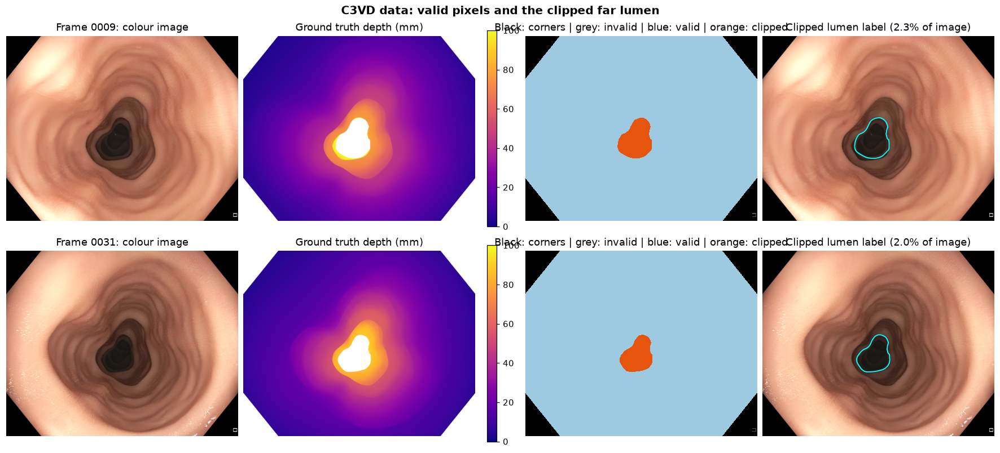

In [30]:
def nanv(a, F):
    return np.where(F["valid"], a, np.nan)


def fig_data(idxs, fname="01_data_and_masks.png"):
    fig, axes = plt.subplots(len(idxs), 4, figsize=(16, 3.6 * len(idxs)), constrained_layout=True)
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        F = FR[i]
        status = np.zeros(F["gt"].shape, np.uint8)
        status[F["fov"]] = 1; status[F["valid"]] = 2; status[F["clipped"]] = 3
        axes[r, 0].imshow(F["rgb"]); axes[r, 0].set_title(f"Frame {F['name']}: colour image")
        im = axes[r, 1].imshow(nanv(F["gt"], F), cmap="plasma", vmin=0, vmax=100)
        axes[r, 1].set_title("Ground truth depth (mm)")
        fig.colorbar(im, ax=axes[r, 1], fraction=0.046)
        axes[r, 2].imshow(status, cmap=plt.matplotlib.colors.ListedColormap(["black", "#555555", "#9ecae1", "#e6550d"]),
                          vmin=0, vmax=3, interpolation="nearest")
        axes[r, 2].set_title("Black: corners | grey: invalid | blue: valid | orange: clipped")
        axes[r, 3].imshow(F["rgb"]); axes[r, 3].contour(F["clipped"], colors="cyan", linewidths=1.2)
        axes[r, 3].set_title(f"Clipped lumen label ({F['clipped'].mean() * 100:.1f}% of image)")
        for a in axes[r]:
            a.axis("off")
    fig.suptitle("C3VD data: valid pixels and the clipped far lumen", fontsize=13, fontweight="bold")
    plt.savefig(fig_dir / fname, dpi=200, bbox_inches="tight"); plt.show()


fig_data([9, 31])

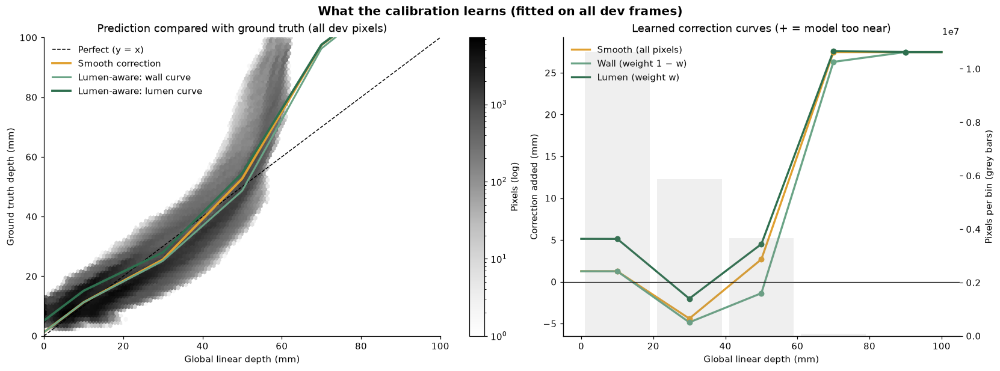

In [33]:
def fig_calibration(P, fname="02_calibration_curves.png"):
    xs, ys = [], []
    for F in FR:
        v = F["valid"]
        xs.append(np.clip(P["a"] * -F["pred"][v][::40] + P["b"], 1e-3, DMAX))
        ys.append(F["gt"][v][::40])
    x, y = np.concatenate(xs), np.concatenate(ys)
    g = np.linspace(0, DMAX, 500)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
    hb = axes[0].hexbin(x, y, gridsize=80, bins="log", cmap="Greys", mincnt=1)
    fig.colorbar(hb, ax=axes[0], label="Pixels (log)")
    axes[0].plot(g, g, "--", color="black", lw=1, label="Perfect (y = x)")
    axes[0].plot(g, g + np.interp(g, *P["curves"]["all"]), color=COLORS[SMO], lw=2.5, label="Smooth correction")
    if "both" in CUES:
        axes[0].plot(g, g + np.interp(g, *P["curves"]["wall_both"]), color="#6aa486", lw=2, label="Lumen-aware: wall curve")
        axes[0].plot(g, g + np.interp(g, *P["curves"]["lumen_both"]), color="#2e6f4e", lw=2.5, label="Lumen-aware: lumen curve")
    axes[0].set(xlabel="Global linear depth (mm)", ylabel="Ground truth depth (mm)", xlim=(0, DMAX), ylim=(0, DMAX),
                title="Prediction compared with ground truth (all dev pixels)")
    axes[0].legend(frameon=False, loc="upper left")

    for name, color, lbl in [("all", COLORS[SMO], "Smooth (all pixels)"),
                             ("wall_both", "#6aa486", "Wall (weight 1 − w)"),
                             ("lumen_both", "#2e6f4e", "Lumen (weight w)")]:
        if name in P["curves"]:
            cx, cy = P["curves"][name]
            axes[1].plot(g, np.interp(g, cx, cy), color=color, lw=2.2, label=lbl)
            axes[1].scatter(cx, cy, color=color, s=30, zorder=3)
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set(xlabel="Global linear depth (mm)", ylabel="Correction added (mm)",
                title="Learned correction curves (+ = model too near)")
    ax2 = axes[1].twinx()
    ax2.bar(CENTERS, P["counts"]["all"], width=18, alpha=0.12, color="grey")
    ax2.set_ylabel("Pixels per bin (grey bars)"); ax2.spines["top"].set_visible(False)
    axes[1].legend(frameon=False, loc="upper left")
    fig.suptitle("What the calibration learns (fitted on all dev frames)", fontsize=13, fontweight="bold")
    plt.savefig(fig_dir / fname, dpi=200, bbox_inches="tight"); plt.show()


fig_calibration(P_final)

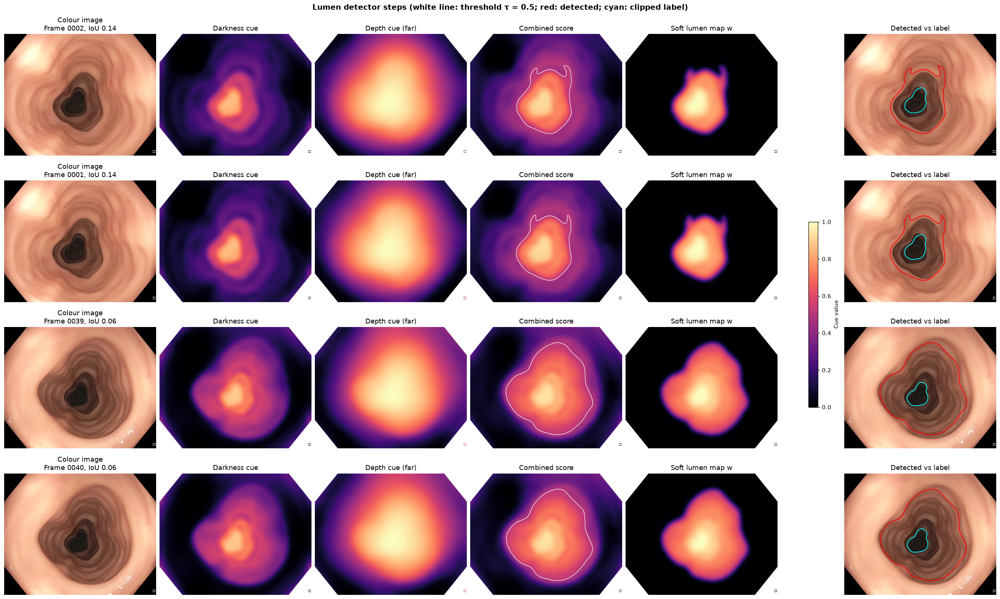

In [34]:
def fig_detector(idxs, fname="03_lumen_detector_steps.png"):
    cols = ["Colour image", "Darkness cue", "Depth cue (far)", "Combined score", "Soft lumen map w", "Detected vs label"]
    fig, axes = plt.subplots(len(idxs), 6, figsize=(24, 3.6 * len(idxs)), constrained_layout=True)
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        F = FR[i]
        dark, far = lumen_cues(F["rgb"], -F["pred"], F["fov"])
        score = np.sqrt(dark * far)
        iou = det.set_index("idx").iou.get(i, np.nan)
        maps = [None, dark, far, score, F["w"]["both"].astype(np.float32), None]
        for c in range(6):
            ax = axes[r, c]
            if c in (0, 5):
                ax.imshow(F["rgb"])
            else:
                im = ax.imshow(np.where(F["fov"], maps[c], np.nan), cmap="magma", vmin=0, vmax=1)
            if c == 3:
                ax.contour(score > TAU, colors="white", linewidths=0.8)
            if c == 5:
                ax.contour(F["clipped"], colors="cyan", linewidths=1.2)
                ax.contour(F["core"], colors="red", linewidths=1.2)
            ax.set_title(f"{cols[c]}" + (f"\nFrame {F['name']}, IoU {iou:.2f}" if c == 0 else ""))
            ax.axis("off")
    fig.colorbar(im, ax=axes[:, 1:5], fraction=0.015, label="Cue value")
    fig.suptitle(f"Lumen detector steps (white line: threshold τ = {TAU}; red: detected; cyan: clipped label)",
                 fontsize=13, fontweight="bold")
    plt.savefig(fig_dir / fname, dpi=200, bbox_inches="tight"); plt.show()


fig_detector(list(det.nlargest(2, "iou").idx) + list(det.nsmallest(2, "iou").idx))

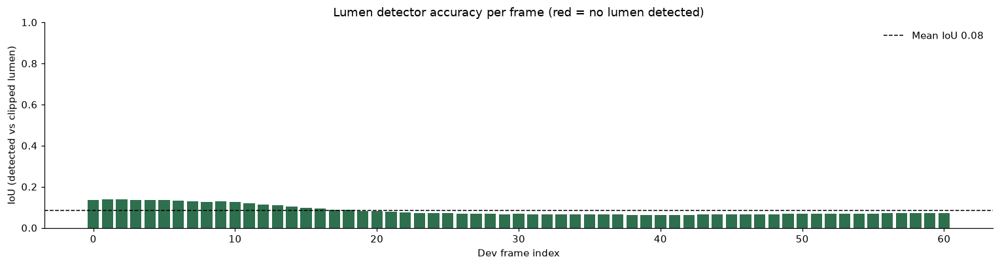

In [35]:
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.bar(det.idx, det.iou, color=np.where(det.detected, "#2e6f4e", "#d62728"), width=0.8)
ax.axhline(det.iou.mean(), color="black", ls="--", lw=1, label=f"Mean IoU {det.iou.mean():.2f}")
ax.set(xlabel="Dev frame index", ylabel="IoU (detected vs clipped lumen)", ylim=(0, 1),
       title="Lumen detector accuracy per frame (red = no lumen detected)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(fig_dir / "04_detector_iou_per_frame.png", dpi=200); plt.show()

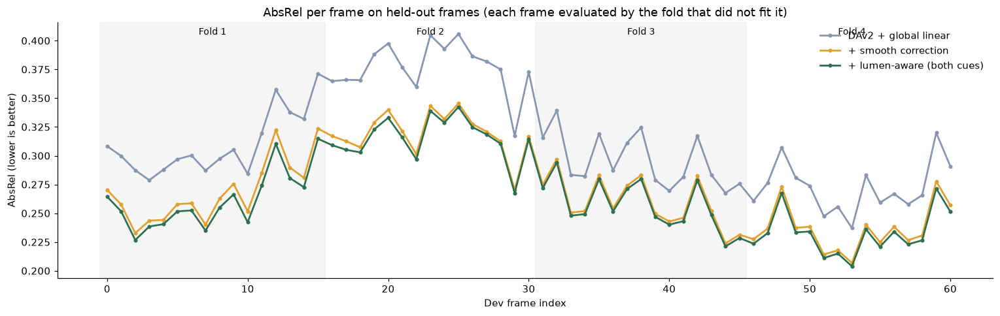

In [36]:
fig, ax = plt.subplots(figsize=(14, 4.5))
for k, (_, te) in enumerate(FOLDS):
    if k % 2 == 0:
        ax.axvspan(min(te) - 0.5, max(te) + 0.5, color="grey", alpha=0.08)
    ax.text(np.mean(te), 0.98, f"Fold {k + 1}", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9)
for label in [LIN, SMO, LUM]:
    d = per_frame[per_frame.method == label].sort_values("idx")
    ax.plot(d.idx, d.absrel, marker="o", ms=3, lw=1.8, color=COLORS[label], label=label)
ax.set(xlabel="Dev frame index", ylabel="AbsRel (lower is better)",
       title="AbsRel per frame on held-out frames (each frame evaluated by the fold that did not fit it)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(fig_dir / "05_absrel_per_frame.png", dpi=200); plt.show()

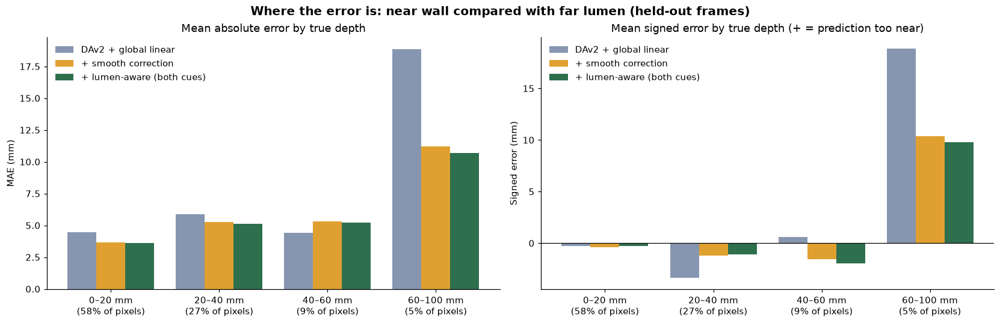

In [28]:
labels_r = [f"{lo}–{hi}" for lo, hi in RANGES]
show_m = [LIN, SMO] + ([LUM] if LUM in range_acc else [])
x = np.arange(len(RANGES)); wdt = 0.8 / len(show_m)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
for j, label in enumerate(show_m):
    acc = range_acc[label]
    mae_r, signed_r = acc[:, 0] / np.maximum(acc[:, 2], 1), acc[:, 1] / np.maximum(acc[:, 2], 1)
    axes[0].bar(x + (j - (len(show_m) - 1) / 2) * wdt, mae_r, wdt, color=COLORS[label], label=label)
    axes[1].bar(x + (j - (len(show_m) - 1) / 2) * wdt, signed_r, wdt, color=COLORS[label], label=label)
pix = range_acc[LIN][:, 2]
for a, ttl, yl in [(axes[0], "Mean absolute error by true depth", "MAE (mm)"),
                   (axes[1], "Mean signed error by true depth (+ = prediction too near)", "Signed error (mm)")]:
    a.set_xticks(x); a.set_xticklabels([f"{l} mm\n({p / pix.sum() * 100:.0f}% of pixels)" for l, p in zip(labels_r, pix)])
    a.set(title=ttl, ylabel=yl); a.legend(frameon=False)
axes[1].axhline(0, color="black", lw=0.8)
fig.suptitle("Where the error is: near wall compared with far lumen (held-out frames)", fontsize=13, fontweight="bold")
plt.savefig(fig_dir / "06_error_by_depth_range.png", dpi=200, bbox_inches="tight"); plt.show()

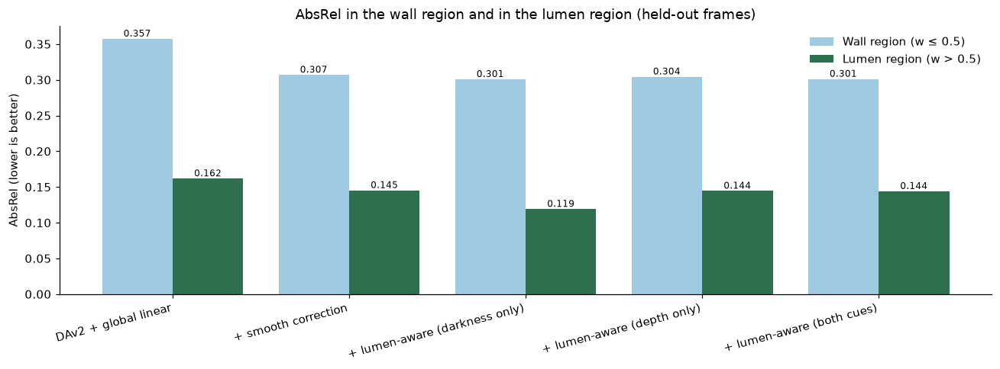

In [29]:
reg = abl.set_index("method")[["absrel_wall", "absrel_lumen"]].loc[[m for m, _, _ in METHODS if m != "Constant median"]]
x = np.arange(len(reg))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - 0.2, reg.absrel_wall, 0.4, color="#9ecae1", label="Wall region (w ≤ 0.5)")
ax.bar(x + 0.2, reg.absrel_lumen, 0.4, color="#2e6f4e", label="Lumen region (w > 0.5)")
for xi, (wv, lv) in enumerate(reg.values):
    ax.text(xi - 0.2, wv, f"{wv:.3f}", ha="center", va="bottom", fontsize=8)
    ax.text(xi + 0.2, lv, f"{lv:.3f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(reg.index, rotation=15, ha="right")
ax.set(ylabel="AbsRel (lower is better)", title="AbsRel in the wall region and in the lumen region (held-out frames)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(fig_dir / "07_wall_vs_lumen.png", dpi=200); plt.show()

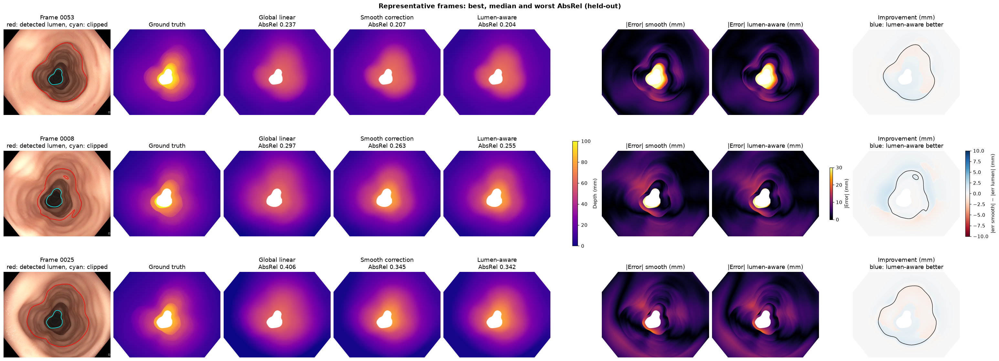

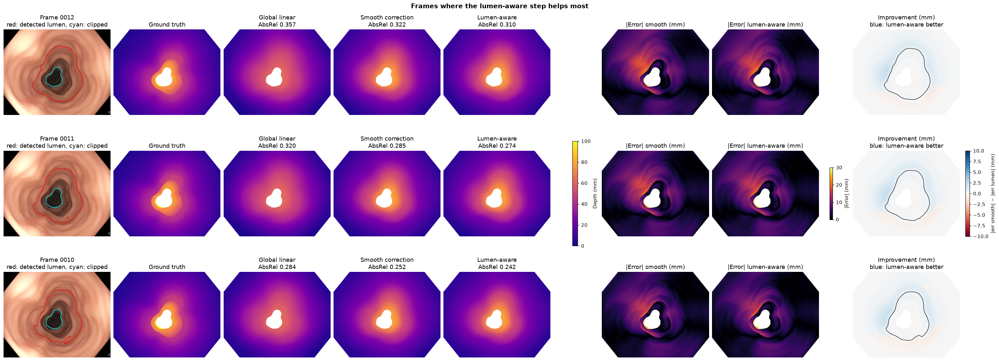

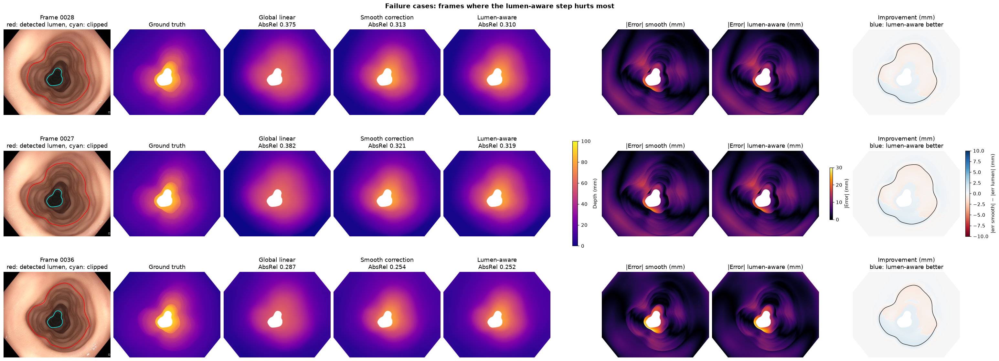

In [30]:
def fig_compare(idxs, title, fname):
    fig, axes = plt.subplots(len(idxs), 8, figsize=(28, 3.5 * len(idxs)), constrained_layout=True)
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        F, P = FR[i], FOLD_PARAMS[HELD[i]]
        lin, sm, lu = predict("linear", F, P), predict("smooth", F, P), predict("lumen", F, P, "both")
        es, el = np.abs(sm - F["gt"]), np.abs(lu - F["gt"])
        ab = {n: frame_metrics(p, F)["absrel"] for n, p in [("lin", lin), ("sm", sm), ("lu", lu)]}
        ax = axes[r]
        ax[0].imshow(F["rgb"]); ax[0].contour(F["core"], colors="red", linewidths=1)
        ax[0].contour(F["clipped"], colors="cyan", linewidths=1)
        ax[0].set_title(f"Frame {F['name']}\nred: detected lumen, cyan: clipped")
        for j, (d, t) in enumerate([(F["gt"], "Ground truth"), (lin, f"Global linear\nAbsRel {ab['lin']:.3f}"),
                                    (sm, f"Smooth correction\nAbsRel {ab['sm']:.3f}"),
                                    (lu, f"Lumen-aware\nAbsRel {ab['lu']:.3f}")], start=1):
            im_d = ax[j].imshow(nanv(d, F), cmap="plasma", vmin=0, vmax=100); ax[j].set_title(t)
        im_e = ax[5].imshow(nanv(es, F), cmap="inferno", vmin=0, vmax=30); ax[5].set_title("|Error| smooth (mm)")
        ax[6].imshow(nanv(el, F), cmap="inferno", vmin=0, vmax=30); ax[6].set_title("|Error| lumen-aware (mm)")
        im_i = ax[7].imshow(nanv(es - el, F), cmap="RdBu", norm=TwoSlopeNorm(0, -10, 10))
        ax[7].contour(F["w"]["both"].astype(np.float32) > 0.5, colors="black", linewidths=0.8)
        ax[7].set_title("Improvement (mm)\nblue: lumen-aware better")
        for a in ax:
            a.axis("off")
    fig.colorbar(im_d, ax=axes[:, 1:5], fraction=0.012, label="Depth (mm)")
    fig.colorbar(im_e, ax=axes[:, 5:7], fraction=0.012, label="|Error| (mm)")
    fig.colorbar(im_i, ax=axes[:, 7], fraction=0.04, label="|err smooth| − |err lumen| (mm)")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.savefig(fig_dir / fname, dpi=200, bbox_inches="tight"); plt.show()


piv = per_frame.pivot(index="idx", columns="method", values="absrel")
gain = (piv[SMO] - piv[LUM]).sort_values()
order = piv[LUM].sort_values()
fig_compare([order.index[0], order.index[len(order) // 2], order.index[-1]],
            "Representative frames: best, median and worst AbsRel (held-out)", "08a_compare_best_median_worst.png")
fig_compare(list(gain.index[-3:][::-1]), "Frames where the lumen-aware step helps most", "08b_compare_helps_most.png")
fig_compare(list(gain.index[:3]), "Failure cases: frames where the lumen-aware step hurts most", "08c_compare_failure_cases.png")

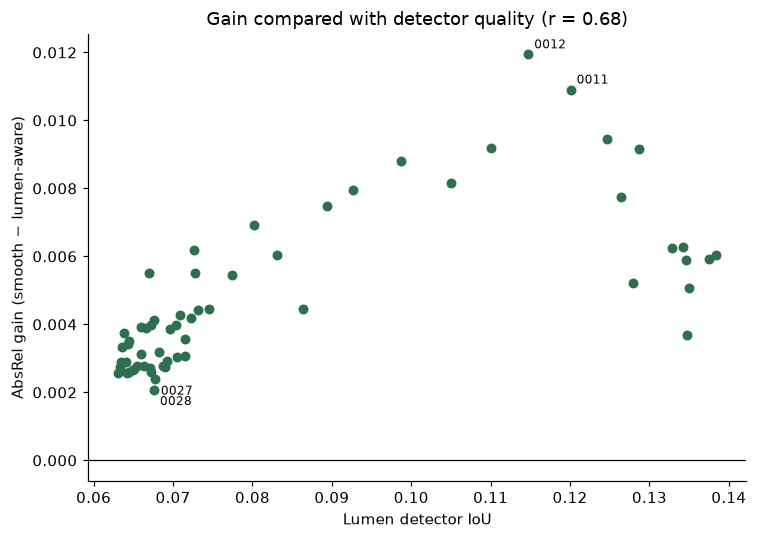

In [31]:
m = det.merge(gain.rename("gain").reset_index(), on="idx")
r = np.corrcoef(m.iou, m.gain)[0, 1] if len(m) > 2 else np.nan
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(m.iou, m.gain, s=30, color="#2e6f4e")
for _, row in m.nlargest(2, "gain").iterrows():
    ax.annotate(row.frame, (row.iou, row.gain), fontsize=8, xytext=(4, 4), textcoords="offset points")
for _, row in m.nsmallest(2, "gain").iterrows():
    ax.annotate(row.frame, (row.iou, row.gain), fontsize=8, xytext=(4, -10), textcoords="offset points")
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Lumen detector IoU", ylabel="AbsRel gain (smooth − lumen-aware)",
       title=f"Gain compared with detector quality (r = {r:.2f})")
plt.tight_layout(); plt.savefig(fig_dir / "09_gain_vs_detector_iou.png", dpi=200); plt.show()

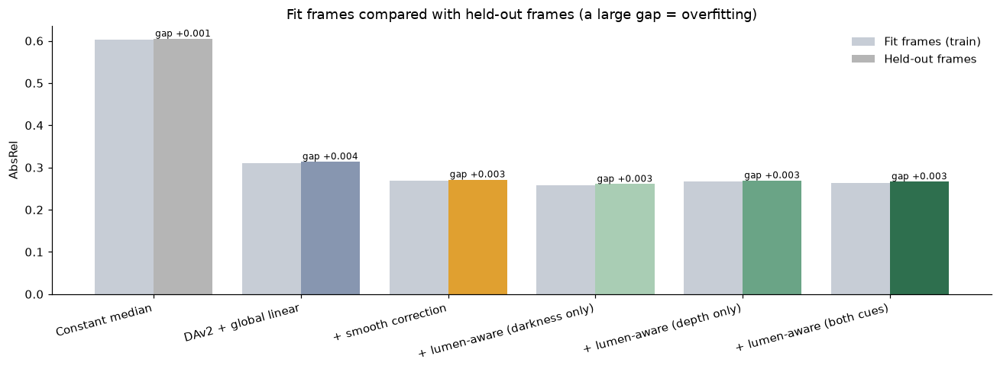

In [32]:
ov = train_test.groupby(["method", "part"], sort=False).absrel.mean().unstack("part")
ov = ov.loc[[mm for mm, _, _ in METHODS]]
x = np.arange(len(ov))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - 0.2, ov["train"], 0.4, color="#c7cdd6", label="Fit frames (train)")
ax.bar(x + 0.2, ov["held-out"], 0.4, color=[COLORS[mm] for mm in ov.index], label="Held-out frames")
for xi, (t, h) in enumerate(ov[["train", "held-out"]].values):
    ax.text(xi + 0.2, h, f"gap {h - t:+.3f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(ov.index, rotation=15, ha="right")
ax.set(ylabel="AbsRel", title="Fit frames compared with held-out frames (a large gap = overfitting)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(fig_dir / "10_train_vs_heldout.png", dpi=200); plt.show()